In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import tqdm
import math
import torch
import numpy as np
from torch import nn
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns

In [2]:
x0_npy = np.load("../data/trajectories_npy/test01/G1_to_S/x0.npy")
x1_npy = np.load("../data/trajectories_npy/test01/G1_to_S/x1.npy")

In [3]:
# Adding random x,y positions on a RNA expression plot
# Adding real x,y coordinates TODO
coords_x0 = np.random.randn(2*x0_npy.shape[0]).reshape((-1,2))
coords_x1 = np.random.randn(2*x1_npy.shape[0]).reshape((-1,2))

x0_npy = np.hstack((x0_npy, coords_x0))
x1_npy = np.hstack((x1_npy, coords_x0))


# Train or load model

## Train model

In [3]:
from src.flow_matching.flow_matching.FM_model import MLP

In [4]:
model = MLP(layers=5, channels_data=7974, channels=512)
optim = torch.optim.AdamW(model.parameters(), lr=1e-4)

In [5]:
from src.flow_matching.flow_matching.FM_train import train_FM

In [6]:
test_name = "test02"
phi_model_path = f"../models/interpolant/{test_name}_interp.pt"

losses_train, losses_test = train_FM(model, phi_model_path, optim, x0_npy, x1_npy, training_steps=100, batch_size=10)

AttributeError: 'numpy.ndarray' object has no attribute 'seek'. You can only torch.load from a file that is seekable. Please pre-load the data into a buffer like io.BytesIO and try to load from it instead.

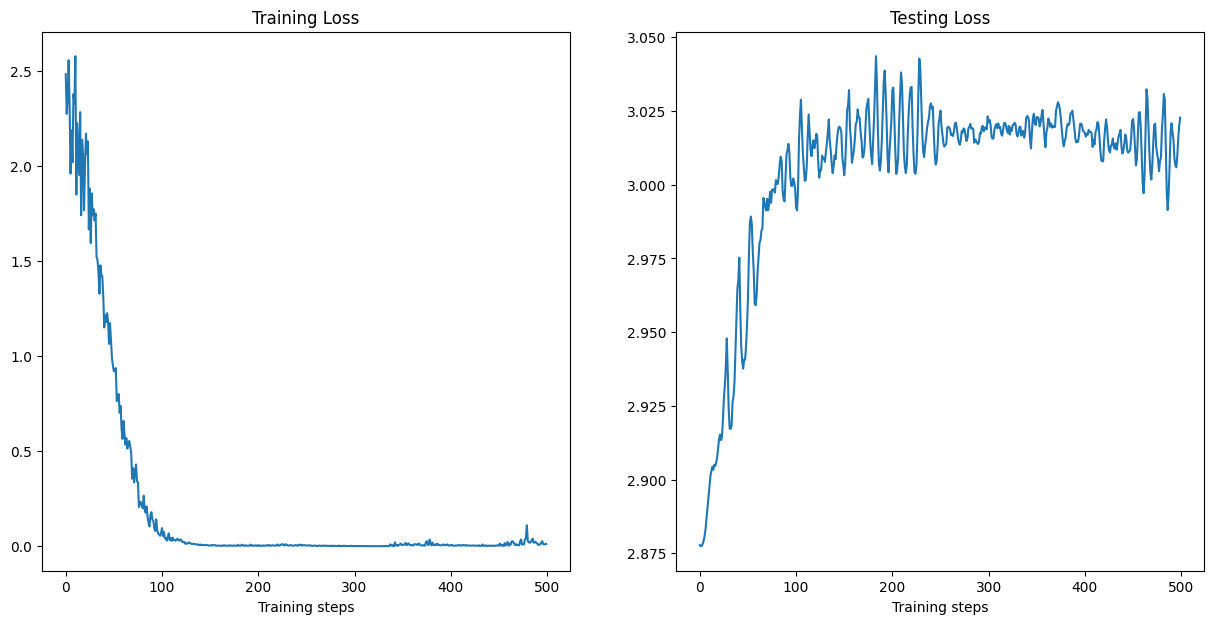

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(15, 7))
ax[0].plot(losses_train)
ax[0].set_title("Training Loss")
ax[0].set_xlabel("Training steps")
ax[1].plot(losses_test)
ax[1].set_title("Testing Loss")
ax[1].set_xlabel("Training steps")

plt.show()

In [96]:
# Save trained model:
torch.save(model.state_dict(), "../models/model_test01.pt")

## Load preexisting model

In [7]:
# Load preptrained model:
model = MLP(layers=5, channels_data=7974, channels=512)
optim = torch.optim.AdamW(model.parameters(), lr=1e-4)
ckpt = torch.load("../models/model_test01.pt")
model.load_state_dict(ckpt)

<All keys matched successfully>

# Iterate trajectory through the vector field

In [8]:
from src.flow_matching.flow_matching.solvers import iterate_trajectory_pytorch

In [9]:
struct_id = 0
x0_vec = x0_npy[struct_id,:].reshape(1,-1)
x1_vec = x1_npy[struct_id,:].reshape(1,-1)
x0_3d =  x0_vec.reshape((int(x0_vec.shape[1]/3), 3))
x1_3d =  x1_vec.reshape((int(x1_vec.shape[1]/3), 3))
# structures = iterate_trajectory(model, x0_vec, time_steps=100, lr=0.01)
structures = iterate_trajectory_pytorch(model, x0_vec)


In [109]:
# project_root = Path.cwd().parent
# if str(project_root) not in sys.path:
#     sys.path.append(str(project_root))
from src.md.visualization_utils import visualize_whole_genome, create_gif

In [114]:
axis_ranges = [x0_3d[:,0].min(), x0_3d[:,0].max(),
               x0_3d[:,1].min(), x0_3d[:,1].max(),
               x0_3d[:,2].min(), x0_3d[:,2].max()]

In [115]:
figs = [visualize_whole_genome(
            points.reshape((int(points.shape[1]/3), 3)), 
            diploid=True, resolution=2_000_000, p=0, title=f"Frame {i}", 
            fig_show=False, axis_range=axis_ranges) \
        for i, points in enumerate(structures)]

In [116]:
create_gif(figs, "./animation.gif", duration=300)

100%|███████████████████████████████████████████| 10/10 [00:15<00:00,  1.54s/it]


# Analyse the iterated trajectory

In [11]:
def rmsd_direct(A: np.ndarray, B: np.ndarray) -> float:
    """Compute direct RMSD between two (m, 3) point sets."""
    return np.sqrt(np.mean(np.sum((A - B) ** 2, axis=1)))

In [24]:
structures[0].reshape(1,-1)

array([[-0.657, 17.02 ,  0.077, ..., -5.056,  2.148, -9.916]],
      shape=(1, 7974), dtype=float32)

In [17]:
[struct.shape[0] for struct in structures]

[7974, 1, 1, 1, 1, 1, 1, 1, 1, 1]

In [30]:
rmsds = [rmsd_direct(struct.reshape((int(struct.shape[1]/3),3)), x1_3d) for struct in structures]

[]

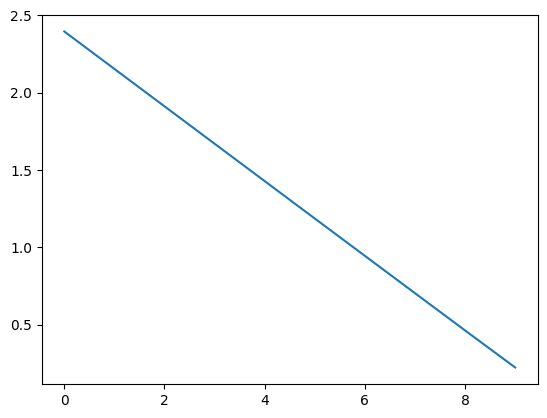

In [31]:
plt.plot(rmsds)
plt.plot()

# Analyse velocity field

In [262]:
struct_id = 0
x0_vec = x0_npy[struct_id,:]
x1_vec = x1_npy[struct_id,:]
x0_3d =  x0_vec.reshape((int(len(x0_vec)/3), 3))
x1_3d =  x1_vec.reshape((int(len(x1_vec)/3), 3))
structures = iterate_trajectory(model, x0_vec, time_steps=400, lr=0.1)

In [32]:
def get_velocity_field(model, x_vec, point_id, coord_id, v_min, v_max, t_points, matrix_size=20):
    x = np.linspace(v_max, v_min, matrix_size)
    t = np.linspace(0, 1, t_points)
    v_field = np.zeros((matrix_size, t_points))

    diff_vec = np.zeros(x_vec.shape)
    for i in range(matrix_size):
        for j in range(t_points):
            diff_vec[point_id*3+coord_id] = x[i]
            v = model(torch.Tensor(x_vec + diff_vec), torch.Tensor([t[j]])).detach().numpy()[0, coord_id]
            v_field[i, j] = v
    return v_field

def get_trajectory(structures, point_id, coord_id):
    return [struct[point_id*3+coord_id] for struct in structures] 


def convert_to_heatmap_coords(values, v_min, v_range, matrix_size):
    return (1-(values-v_min)/v_range)*(matrix_size-1) + 0.5

def plot_velocity_fields(model, structures, x1_vec, n_points=2, matrix_size=20):

    velocities = []
    differences = []
    
    fig, ax = plt.subplots(n_points, 3, figsize=(15, 10))
    for i in range(n_points):
        for j in range(3):
            values = np.array([struct[0,3*i+j] for struct in structures] + [x1_vec[3*i+j]], dtype=float)
            v_min = np.min(values)
            v_max = np.max(values)
            v_range = v_max - v_min
            v_min -= v_range*0.1
            v_max += v_range*0.1
            v_range = v_max - v_min
            v_field = get_velocity_field(model, structures[0][0], i, j, v_min, v_max, t_points=len(structures), matrix_size=matrix_size)

            if i==0 and j==1:
                for k in range(len(structures)-1):
                    velocities.append(v_field[0, k])
                    differences.append(structures[k+1][0,3*i+j] - structures[k][0,3*i+j])
            
            sns.heatmap(v_field, cmap="viridis", ax=ax[i][j])
            ax[i][j].set_title(f"Point {i}, coord {j}")
            ax[i][j].plot(
                np.arange(len(values)-1) + 0.5,
                convert_to_heatmap_coords(values[:-1], v_min, v_range, matrix_size),
                color="white", marker="o", markersize=8, linewidth=2, linestyle="-", label="Trajectory",
            )
            
            ax[i][j].plot(
                np.array([-0.5, len(structures)+0.5]),
                convert_to_heatmap_coords(np.array([structures[0][0, 3*i+j], structures[0][0, 3*i+j]]), v_min, v_range, matrix_size),
                color="white", linewidth=2, linestyle="--", label="x0",
            )
            ax[i][j].plot(
                np.array([-0.5, len(structures)+0.5]),
                convert_to_heatmap_coords(np.array([x1_vec[3*i+j], x1_vec[3*i+j]]), v_min, v_range, matrix_size),
                color="white", linewidth=2, linestyle="--", label="x1",
            )
    plt.show()
    return velocities, differences

ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (11,) + inhomogeneous part.

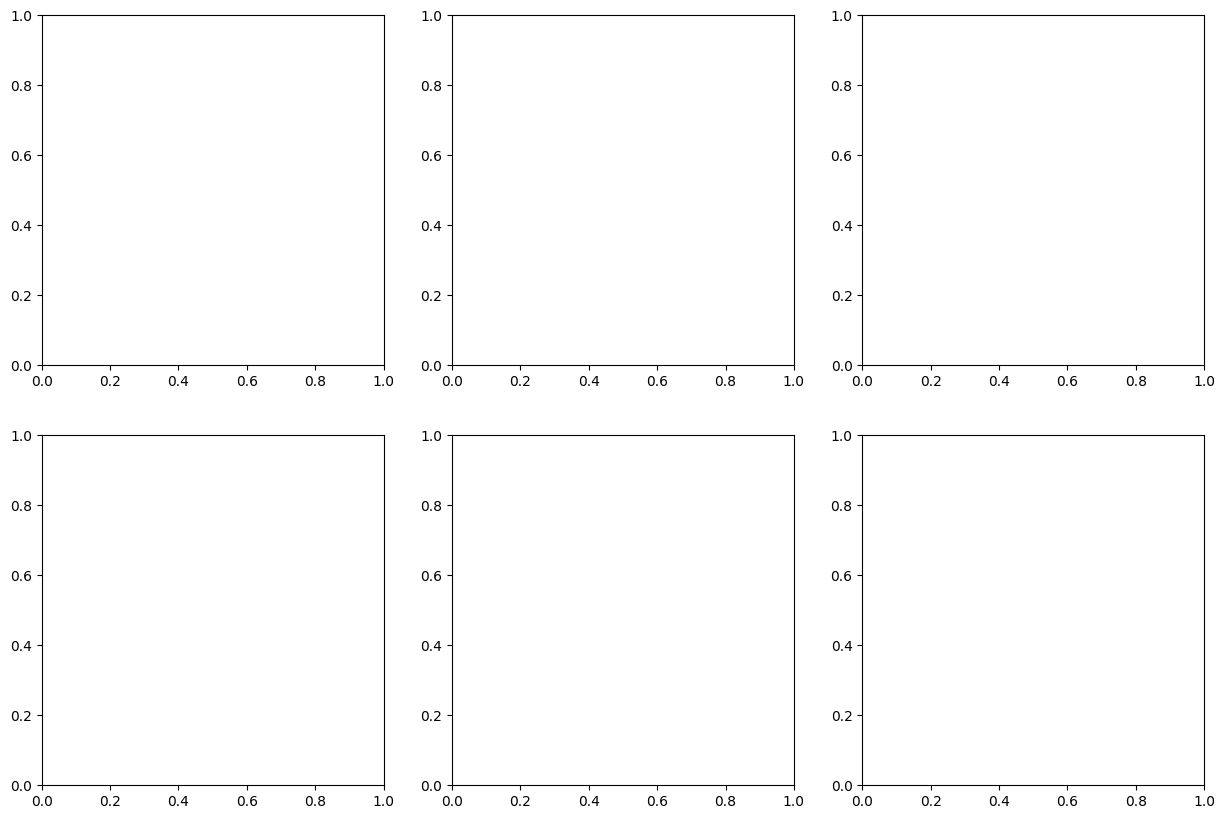

In [33]:
velocities, differences = plot_velocity_fields(model, structures, x1_vec, n_points=2)

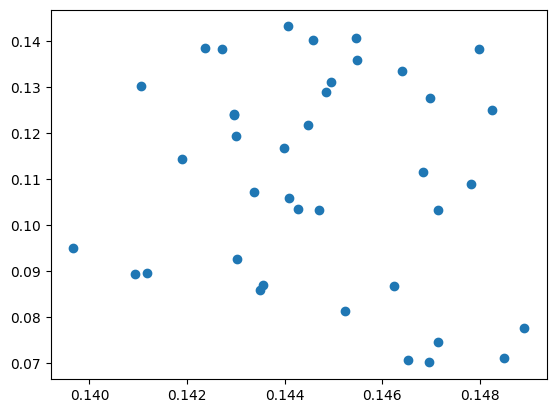

In [265]:
plt.scatter(velocities, differences)
plt.show()

/home/baneckik/Programs/miniconda3/lib/python3.13/site-packages/torch/cuda/__init__.py:188: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12020). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


Showing velocity field background (Swirl) on the X-Y Plane, fixed at Z=0.93


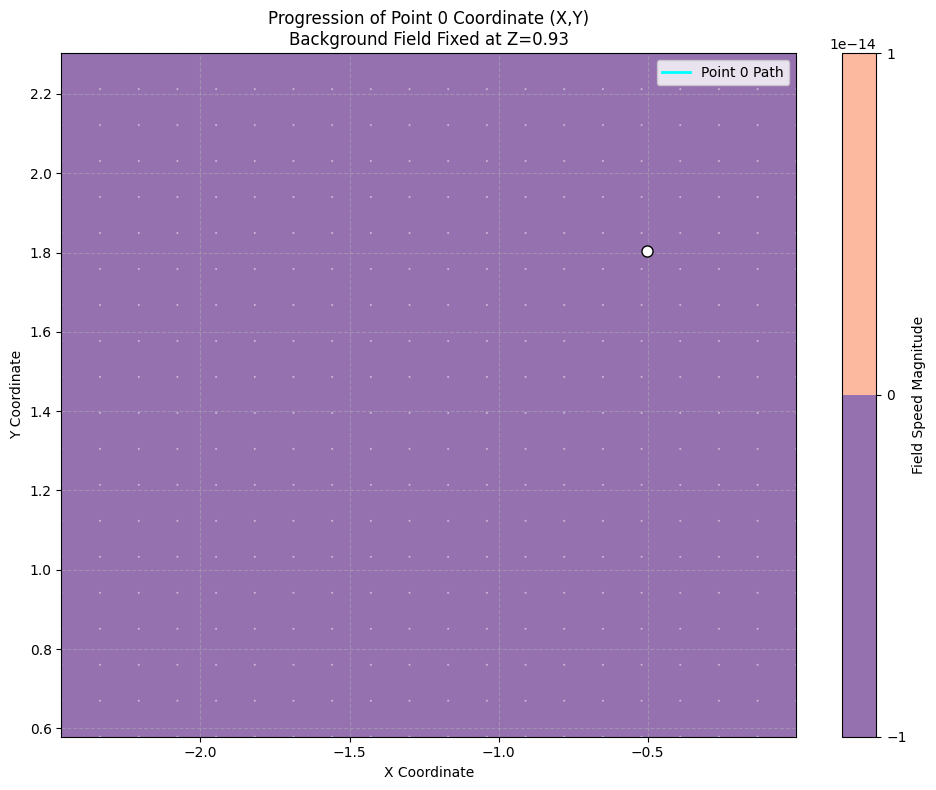

In [34]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.animation import FuncAnimation

# ==========================================
# PART 1: Define a Mock Model for standard testing
# ==========================================
class MockVelocityModel(torch.nn.Module):
    """
    A simple analytic model to generate a vortex-like velocity field
    for demonstration purposes. 
    It expects input flattened (m*3,) and returns velocity (m*3,).
    """
    def __init__(self, num_points):
        super().__init__()
        self.m = num_points

    def forward(self, x, t):
        # x shape assumed: (m*3,)
        device = x.device
        x_reshaped = x.view(self.m, 3)
        
        # Analytic field: v_x = -y, v_y = x, v_z = 0.1 (simple swirl)
        # Add some time-dependence and z-dependence for complexity
        u = -x_reshaped[:, 1] * torch.cos(t) - 0.1 * x_reshaped[:, 2]
        v = x_reshaped[:, 0] * torch.sin(t)
        w = 0.1 * torch.ones_like(u)
        
        # Return flattened (m*3,)
        return torch.stack([u, v, w], dim=1).view(-1).to(device)

# ==========================================
# PART 2: Optimized Integration Function (RK4)
# ==========================================
@torch.no_grad()
def iterate_trajectory_rk4(model, x0_np, time_end=1.0, num_steps=100, save_every=1):
    """
    x0_np: numpy array, shape (m, 3) flattened to (m*3,)
    """
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    x_curr = torch.tensor(x0_np, dtype=torch.float32, device=device)
    t_span = torch.linspace(0.0, time_end, num_steps, device=device)
    dt = t_span[1] - t_span[0]
    
    full_trajectory = []
    # Save initial state
    full_trajectory.append(x_curr.cpu().numpy())
    
    model.to(device)
    model.eval()
    
    for i in range(len(t_span) - 1):
        t = t_span[i]
        
        # RK4 Steps
        k1 = model(x_curr, t)
        k2 = model(x_curr + 0.5 * dt * k1, t + 0.5 * dt)
        k3 = model(x_curr + 0.5 * dt * k2, t + 0.5 * dt)
        k4 = model(x_curr + dt * k3, t + dt)
        
        x_curr = x_curr + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)
        
        if (i + 1) % save_every == 0:
            full_trajectory.append(x_curr.cpu().numpy())
            
    return np.array(full_trajectory), t_span.cpu().numpy()

# ==========================================
# PART 3: MAIN: Generate and Visualize
# ==========================================

# --- 1. Simulation Parameters ---
M_POINTS = 5 # How many points in our structure
T_STEPS = 200 # How many integration steps to take
LR = 0.1     # Learning rate used originally (we use dt instead in RK4)

# Define initial structure x0: shape (M, 3) flattened
np.random.seed(42)
x0_points = np.random.uniform(-2, 2, (M_POINTS, 3))
x0_flat = x0_points.flatten()

# Instantiate the model
# (SWAP WITH YOUR TRAINED MODEL HERE)
my_model = MockVelocityModel(num_points=M_POINTS)

# Run optimized integration
# We use T_STEPS to define dt, rather than LR.
trajectory_flat, times = iterate_trajectory_rk4(my_model, x0_flat, num_steps=T_STEPS)

# trajectory_flat shape: (Num_saved_steps, M_POINTS*3)
# Reshape for easier access: (Num_saved_steps, M_POINTS, 3 coordinates)
trajectory = trajectory_flat.reshape(trajectory_flat.shape[0], M_POINTS, 3)


# --- 2. Visualization Parameters ---
# Select JUST ONE POINT to track
POINT_IDX_TO_PLOT = 0 
# Select WHICH TWO coordinates to use as the 2D plane
# 0=X, 1=Y, 2=Z. E.g., Plane = XY
PLANE_AXES = (0, 1)   
coords_labels = ['X', 'Y', 'Z']

# Get the fixed coordinate idx (the one not in PLANE_AXES)
all_axes = {0, 1, 2}
FIXED_AXIS_IDX = list(all_axes - set(PLANE_AXES))[0]

# --- 3. Compute Velocity Field Background ---
# We need to create a grid in the PLANE, query model at a FIXED 3rd coord.

# Define background grid limits based on trajectory spread
plot_pts = trajectory[:, POINT_IDX_TO_PLOT, :]
margin = 0.5
x_min, x_max = plot_pts[:, PLANE_AXES[0]].min() - margin, plot_pts[:, PLANE_AXES[0]].max() + margin
y_min, y_max = plot_pts[:, PLANE_AXES[1]].min() - margin, plot_pts[:, PLANE_AXES[1]].max() + margin

# Create Grid
grid_res = 20
X_grid, Y_grid = np.meshgrid(np.linspace(x_min, x_max, grid_res),
                             np.linspace(y_min, y_max, grid_res))

# Important: To show the field background, we must fix the 3rd coordinate.
# We will fix it at the STARTING position of the selected point.
fixed_coord_val = trajectory[0, POINT_IDX_TO_PLOT, FIXED_AXIS_IDX]
print(f"Showing velocity field background (Swirl) on the "
      f"{coords_labels[PLANE_AXES[0]]}-{coords_labels[PLANE_AXES[1]]} Plane, "
      f"fixed at {coords_labels[FIXED_AXIS_IDX]}={fixed_coord_val:.2f}")

# Prepare batch input for the model to get velocities over the whole grid
grid_points_flat = np.zeros((grid_res * grid_res, 3))
grid_points_flat[:, PLANE_AXES[0]] = X_grid.flatten()
grid_points_flat[:, PLANE_AXES[1]] = Y_grid.flatten()
grid_points_flat[:, FIXED_AXIS_IDX] = fixed_coord_val # Fix 3rd dimension

# The model expects m=M_POINTS points flattened. 
# To query a single gridpoint, we "mock" a structure of M points, 
# where point 0 is our gridpoint, and others are dummy (zeros).
mock_structure = np.zeros((M_POINTS, 3))

U_grid = np.zeros_like(X_grid)
V_grid = np.zeros_like(Y_grid)

# Query model at each grid point (or batch it if model supports)
# We show the field at t=0 for the static background.
my_model.cpu() # Run field generation on CPU
my_model.eval()

with torch.no_grad():
    for i in range(grid_res * grid_res):
        mock_structure[POINT_IDX_TO_PLOT] = grid_points_flat[i]
        input_tensor = torch.tensor(mock_structure.flatten(), dtype=torch.float32)
        
        v_flat = my_model(input_tensor, torch.tensor([0.0])) # t=0
        v_points = v_flat.numpy().reshape(M_POINTS, 3)
        
        # Extract the velocity components corresponding to our plane
        U_grid.flatten()[i] = v_points[POINT_IDX_TO_PLOT, PLANE_AXES[0]]
        V_grid.flatten()[i] = v_points[POINT_IDX_TO_PLOT, PLANE_AXES[1]]

# Calculate speed for coloring
speed = np.sqrt(U_grid**2 + V_grid**2)


# --- 4. Plotting ---
fig, ax = plt.subplots(figsize=(10, 8))

# Background: Underlying Velocity Field Magnitude (Speed)
cf = ax.contourf(X_grid, Y_grid, speed, cmap='magma', alpha=0.6, levels=20)
fig.colorbar(cf, label='Field Speed Magnitude')

# Background: Field Direction (Arrows)
ax.quiver(X_grid, Y_grid, U_grid, V_grid, color='white', alpha=0.5, scale=20)

# The Trajectory of the SINGLE point (the progression path)
traj_x = trajectory[:, POINT_IDX_TO_PLOT, PLANE_AXES[0]]
traj_y = trajectory[:, POINT_IDX_TO_PLOT, PLANE_AXES[1]]
line, = ax.plot(traj_x, traj_y, color='cyan', linewidth=2, label=f'Point {POINT_IDX_TO_PLOT} Path')

# The current head of the trajectory
point_head, = ax.plot([], [], 'o', color='white', markersize=8, markeredgecolor='black')

# Aesthetics
ax.set_xlabel(f'{coords_labels[PLANE_AXES[0]]} Coordinate')
ax.set_ylabel(f'{coords_labels[PLANE_AXES[1]]} Coordinate')
ax.set_title(f'Progression of Point {POINT_IDX_TO_PLOT} Coordinate ({coords_labels[PLANE_AXES[0]]},{coords_labels[PLANE_AXES[1]]})\n'
             f'Background Field Fixed at {coords_labels[FIXED_AXIS_IDX]}={fixed_coord_val:.2f}')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)

# Optional Animation Function to see progression
def animate(i):
    # Update line data up to current frame
    line.set_data(traj_x[:i], traj_y[:i])
    # Update current point position
    point_head.set_data(traj_x[i:i+1], traj_y[i:i+1])
    return line, point_head

# Create the animation
ani = FuncAnimation(fig, animate, frames=len(times), interval=50, blit=True)

plt.tight_layout()
plt.show()

In [119]:
row_id = np.random.randint(x0_npy.shape[0])
coord_id = np.random.randint(x0_npy.shape[1])
x_radius = 10

n = 30
x = np.linspace(x0_npy[row_id, coord_id]-x_radius, x0_npy[row_id, coord_id]+x_radius, n)
t = np.linspace(0, 1, n)
v_field = np.zeros((n, n))

x0_row = x0_npy[row_id,:].copy()
for i in range(n):
    for j in range(n):
        v = model(torch.Tensor(x0_row + x[i]), torch.Tensor([t[j]])).detach().numpy()[0, coord_id]
        v_field[i, j] = v

print(f"Starting value: { x0_npy[row_id, coord_id] }")
print(f"Ending value: { x1_npy[row_id, coord_id] }")


Strating value: -3.549
Ending value: -4.117


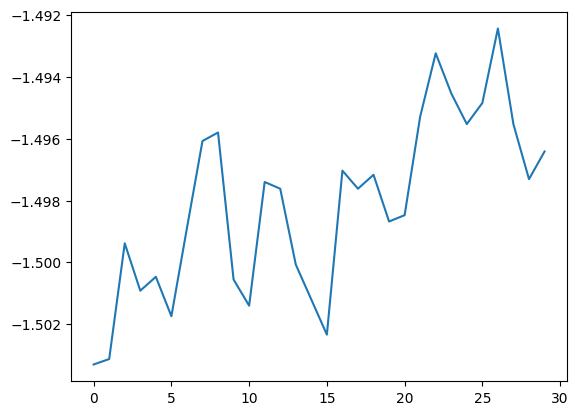

In [178]:
plt.plot(v_field[15,:])

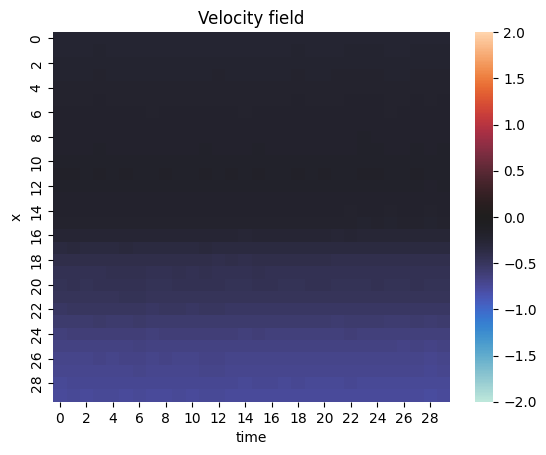

In [120]:
sns.heatmap(v_field, vmin=-2, vmax=2, cmap="icefire")
plt.title("Velocity field")
plt.xlabel("time")
plt.ylabel("x")
plt.show()

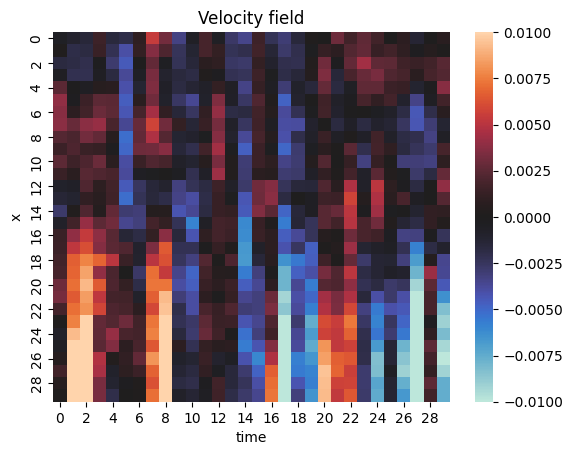

In [184]:
sns.heatmap(v_field -v_field.mean(axis=1, keepdims=True), vmin=-0.01, vmax=0.01, cmap="icefire")
plt.title("Velocity field")
plt.xlabel("time")
plt.ylabel("x")
plt.show()